# 09 · Lilis no código híbrido da cozinha

**Pergunta:** usar os volumes dos ambientes e das aberturas ajuda nosso código a construir e examinar os limites da cozinha?

Agora executamos uma **adaptação parcial de operadores**, além da triagem anterior. Em linguagem simples: projetamos a face principal das aberturas sobre as faces do ambiente, recortamos o que coincide e calculamos o que sobra. Depois comparamos com o resultado anterior e com o volume real da abertura.

**Fonte principal:** Lilis, G. N.; Bouquerel, M.; Wang, M.; Katsigarakis, K.; Korolija, I.; Rovas, D. (2026). *Automated generation of building energy model geometry from BIM-derived space and opening volumes*. Automation in Construction, 185, 106840. [DOI](https://doi.org/10.1016/j.autcon.2026.106840) · [PDF e registro UCL](https://discovery.ucl.ac.uk/id/eprint/10222561/).

Usamos §§2.1–2.2 e 3.3.1–3.3.4, Eq. 1 e 5, Alg. 1–3 e 5, parcialmente adaptados. **Alpha wrap/Alg. 4 não foi implementado; não há classificação externa certificada nem execução completa nos 41 cômodos.** O código Python foi reimplementado a partir do artigo e não é o programa C++ dos autores. O IFC original não é regravado.

In [1]:
# 1. Bibliotecas. As funções geométricas serão importadas do pacote verificado.
# Fontes técnicas: IfcOpenShell geometry_processing; OCP; Shapely intersection;
# RDFLib intro_to_graphs. As versões efetivas são registradas no final.
from pathlib import Path
import os,sys,json,hashlib,zipfile,shutil,subprocess,importlib.util
from urllib.request import urlretrieve
dependencias={'numpy':'numpy','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
faltantes=[p for m,p in dependencias.items() if importlib.util.find_spec(m) is None]
if faltantes:subprocess.check_call([sys.executable,'-m','pip','install',*faltantes])
import numpy,ifcopenshell,OCP,shapely,rdflib,matplotlib
RAIZ=Path(os.environ.get('CIV2155_LILIS_RAIZ','CIV2155_Lilis_Hibrido_v01')).resolve()
RAIZ.mkdir(parents=True,exist_ok=True)
print('IfcOpenShell',ifcopenshell.version,'OCP',OCP.__version__,'Shapely',shapely.__version__,'RDFLib',rdflib.__version__)


IfcOpenShell 0.8.4 OCP 7.8.1.1 Shapely 2.2.0 RDFLib 7.1.4


## Entradas preservadas e sua função

O pacote inclui o código desta adaptação, as interfaces híbridas já calculadas, a triagem dos espaços e o RDF anterior. As avaliações IFC2SB/Krijnen/Kiavarz são reutilizadas; seus motores não são reexecutados neste notebook. O processamento de Lilis será executado sobre o IFC original.

O pacote e o IFC têm seus SHA-256 conferidos antes do uso. Para execução local, duas variáveis opcionais permitem usar cópias dos mesmos arquivos; o caminho local não dispensa a conferência. Sem essas variáveis, os arquivos são baixados de uma revisão fixa do GitHub.

In [2]:
# 2. Carrega as entradas fixadas. O pacote foi publicado antes deste notebook.
SNAPSHOT='7507e4e318942ca7cd11b22f4a37a71cdeb9895d'
BASE='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/'
PACOTE=RAIZ/'Pacote_Lilis_Hibrido_v01.zip'
local=os.environ.get('CIV2155_LILIS_PACOTE')
if local:shutil.copy2(local,PACOTE)
else:urlretrieve(BASE+'resultados/lilis_hibrido_v01/Pacote_Lilis_Hibrido_v01.zip',PACOTE)
assert hashlib.sha256(PACOTE.read_bytes()).hexdigest()=='919be6dc320376d615000fdfb508571b6a7bff8cfe9dbfac1eafd04f1caf6b1c'
with zipfile.ZipFile(PACOTE) as z:z.extractall(RAIZ)
IFC=RAIZ/'TIPO2-ARQ-DTV_R03.ifc'
local=os.environ.get('CIV2155_LILIS_IFC')
if local:shutil.copy2(local,IFC)
else:
    compactado=RAIZ/'Arquitetura_Original.zip'
    urlretrieve(BASE+'dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip',compactado)
    with zipfile.ZipFile(compactado) as z:IFC.write_bytes(z.read(IFC.name))
IFC_SHA='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert hashlib.sha256(IFC.read_bytes()).hexdigest()==IFC_SHA
sys.path.insert(0,str(RAIZ/'codigo'))
SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
ENTRADA=RAIZ/'entrada'
fontes=json.loads((RAIZ/'referencias/Fontes_e_Adaptacoes_Lilis_v01.json').read_text(encoding='utf8'))
print('Pacote e IFC conferidos por SHA-256. Revisão:',SNAPSHOT)


Pacote e IFC conferidos por SHA-256. Revisão: 7507e4e318942ca7cd11b22f4a37a71cdeb9895d


## Controles antes da creche

Os 20 controles usam dimensões simples com resultado calculável: faces separadas, limiar estrito, orientação, projeção inclinada, recorte parcial, contato por aresta, furo, cópias transladadas/rotacionadas e aberturas sobrepostas. O teste de `maxA` confirma que o algoritmo não escolhe uma face menor apenas para forçar uma associação.

Isso verifica o comportamento dos operadores adaptados. Não demonstra equivalência completa ao programa dos autores nem valida o projeto arquitetônico.

In [3]:
# 3. Testa IP/IPS (§2.1), PSS (§2.2), maxA/Alg. 5 (§3.3.4).
from controles_lilis import run as testar
controles=testar(SAIDA)
assert controles['total']==controles['aprovados']==20


Controles Lilis: 20 aprovados


## Aplicação ao piloto: o que vem de Lilis e o que adaptamos

| Etapa | Fonte e aplicação |
|---|---|
| Projetar faces e intersectar | Lilis §2.1/Eq. 1/Alg. 1. Cada resultado permanece no seu plano. |
| Calcular resíduos | §2.2/Alg. 2. Subtrair a união dos recortes evita descontar uma sobreposição duas vezes. |
| Relacionar faces entre espaços | §3.3.1/Alg. 3, limitado a pares cozinha/outro espaço aceitos e sem sobreposição volumétrica no critério. |
| Selecionar a face principal da abertura | §3.3.4/Eq. 5/Alg. 5. Uma face global `maxA`; testar sua orientação e a orientação invertida. |
| Associar à parede e à interface híbrida | Extensão deste estudo: usar o hospedeiro IFC e a localização do recorte. |
| Conferir com o volume real | Extensão deste estudo: Common 3D entre interface e abertura. Não é condição exigida por Lilis nem padrão-ouro arquitetônico. |

**Diferença relevante:** no artigo, o Alg. 5 recebe limites classificados nas etapas anteriores. Aqui recebe faces brutas do espaço e seus recortes são cruzados com as interfaces anteriores. Essa substituição permite testar a contribuição dos operadores, mas impede apresentar o ensaio como reprodução do fluxo completo.

Shapely substitui Clipper; a base local e os anéis vêm do módulo anterior de Kiavarz. A tolerância PSS é 10⁻⁷ m, escolha do estudo; `eps_normal = 10⁻³` se apoia no §4. Empates `maxA` mantêm a ordem das faces. A distância principal é 30 cm, com ensaios em 5, 15 e 60 cm; não afirmamos que 30 cm seja o valor ótimo. Volumes compostos são preservados. A variante por componente é registrada separadamente.

In [4]:
# 4. Examina as 184 aberturas do IFC; a caixa espacial é apenas pré-filtro.
# Recalcula o ensaio no IFC e compara projeção com interseção 3D independente.
from ensaio_lilis import run as processar
resultado=processar(IFC,ENTRADA/'Resultado_Hibrido_Kiavarz_v01.json',ENTRADA/'Triagem_Precondicoes_Lilis_2026_v01.json',SAIDA)
s=resultado['resumo']
assert s['aberturas_ifc_examinadas']==184 and s['aberturas_no_ensaio_local']==26
assert s['aberturas_associadas_antes']==s['aberturas_associadas_apos']==10
assert s['recortes_hibridos']==12 and s['recortes_com_apoio_volume_3D']==11
assert s['recortes_sem_apoio_volume_3D']==1
assert not s['novas_associacoes_candidatas'] and not s['associacoes_anteriores_nao_reproduzidas']


{
  "aberturas_ifc_examinadas": 184,
  "aberturas_no_ensaio_local": 26,
  "faces_espaco": 23,
  "pares_faces_espacos_candidatos": 11,
  "recortes_brutos_alg5": 33,
  "recortes_hibridos": 12,
  "aberturas_associadas_antes": 10,
  "aberturas_associadas_apos": 10,
  "novas_associacoes_candidatas": [],
  "associacoes_anteriores_nao_reproduzidas": [],
  "interfaces_com_area_residual": 14,
  "area_bruta_interfaces_m2": 91.98278742515194,
  "area_recortes_uniao_m2": 11.936844023101573,
  "area_residual_m2": 80.04594340205037,
  "recortes_com_apoio_volume_3D": 11,
  "recortes_sem_apoio_volume_3D": 1,
  "area_uniao_recortes_apoiados_3D_m2": 11.874844023101693,
  "area_residual_apos_recortes_apoiados_3D_m2": 80.10794340205024,
  "tolerancia_area_conferencia_m2": 1e-07
}


## Leitura dos resultados e do caso adicional

Mantivemos dez aberturas distintas. Elas geram 12 recortes locais candidatos: 11 com apoio no volume 3D e um adicional de **0,062 m²** que só aparece pela projeção. Esse recorte extra fica na interface `I_W12_F000_R17_P0`, abertura `3jgqqodbWPKg146xEcFt2w`.

Lilis permite projetar entre planos separados. Portanto, ausência de Common 3D não prova falha do operador. Para o nosso objetivo de associar elementos à cozinha, registramos o recorte separadamente e deixamos a interpretação arquitetônica pendente.

As 14 interfaces somam cerca de 91,982787 m². A união dos recortes candidatos soma 11,936844 m², com resíduo de 80,045943 m². Usar apenas os recortes apoiados pelo volume produz uma alternativa de 11,874844 m² e 80,107943 m². **Essas alternativas não devem ser somadas, nem chamadas de área de vidro ou parede opaca certificada.** As áreas são somadas por interface, sem deduplicar superfícies físicas em planos diferentes.

Em 5 cm, três aberturas são associadas; em 15, 30 e 60 cm, dez. A estabilidade da contagem não prova igualdade das geometrias ou acurácia.

In [5]:
# 5. Exibe a sensibilidade e verifica o balanço sem dupla subtração.
for r in resultado['sensibilidade']:
    print(r['d_m'],'m |',r['variante'],'| brutos:',r['recortes_brutos'],'| aberturas:',r['aberturas_com_interface_hospedeira'])
extras=[r for r in resultado['comparacao_geometrica'] if r['area_lilis_sem_apoio_common_3D_m2']>1e-7]
assert len(extras)==1 and abs(extras[0]['area_lilis_sem_apoio_common_3D_m2']-.062)<1e-7
print('Recorte que requer conferência:',json.dumps(extras,ensure_ascii=False,indent=2))
assert all(r['conservacao_area'] for r in resultado['areas_por_interface'])
assert abs(s['area_bruta_interfaces_m2']-s['area_recortes_uniao_m2']-s['area_residual_m2'])<1e-7


0.05 m | maxA_global_artigo | brutos: 15 | aberturas: 3
0.05 m | maxA_por_componente_extensao | brutos: 23 | aberturas: 3
0.15 m | maxA_global_artigo | brutos: 27 | aberturas: 10
0.15 m | maxA_por_componente_extensao | brutos: 38 | aberturas: 10
0.3 m | maxA_global_artigo | brutos: 33 | aberturas: 10
0.3 m | maxA_por_componente_extensao | brutos: 45 | aberturas: 10
0.6 m | maxA_global_artigo | brutos: 47 | aberturas: 10
0.6 m | maxA_por_componente_extensao | brutos: 59 | aberturas: 10
Recorte que requer conferência: [
  {
    "interface": "I_W12_F000_R17_P0",
    "abertura": "3jgqqodbWPKg146xEcFt2w",
    "area_anterior_m2": 0.0,
    "area_lilis_m2": 0.06199999999984449,
    "area_intersecao_anterior_m2": 0.0,
    "area_nova_m2": 0.06199999999984449,
    "area_anterior_nao_reproduzida_m2": 0.0,
    "area_diferenca_simetrica_m2": 0.06199999999984449,
    "area_common_3D_m2": 0.0,
    "area_lilis_apoiada_common_3D_m2": 0.0,
    "area_lilis_sem_apoio_common_3D_m2": 0.06199999999984449
  }


## Integração no grafo por cômodo

O RDF anterior conserva IFC2SB, Krijnen e Kiavarz. As evidências de Lilis são acrescentadas com um vocabulário próprio: cozinha → recorte candidato → interface anterior → parede, abertura e preenchimento. Cada recorte informa área, coordenadas XYZ, apoio 3D e proveniência. A consulta inclui os casos sem apoio, para que eles não desapareçam da análise.

As áreas residuais e os pares entre espaços são registrados como evidências candidatas. Não acrescentamos novas adjacências BOT certificadas nem substituímos as relações anteriores. A organização RDF é uma extensão deste estudo, com serialização GEOM baseada em Zhang, Beetz e de Vries (2018), [DOI 10.3233/SW-180297](https://doi.org/10.3233/SW-180297), e biblioteca RDFLib.

In [6]:
# 6. Preserva o grafo v06, acrescenta as evidências e consulta o resultado.
from exportar_lilis import run as exportar
registro=exportar(SAIDA/'Resultado_Lilis_Hibrido_v01.json',ENTRADA/'Cozinha_Interfaces_Hibridas_IFC2SB_Krijnen_Kiavarz_v01.ttl',SAIDA)
assert registro['triplas_entrada']==2559 and registro['triplas_saida']==3244
g=rdflib.Graph().parse(SAIDA/'Cozinha_Hibrido_Com_Ensaio_Lilis_v01.ttl',format='turtle')
linhas=list(g.query((SAIDA/'Consultar_Recortes_Lilis.rq').read_text(encoding='utf8')))
assert len(linhas)==12
for linha in linhas:print(str(linha.recorte).rsplit('/',1)[-1],float(linha.area),'m² | apoio3D:',linha.apoio3D)


{
  "triplas_entrada": 2559,
  "triplas_saida": 3244,
  "linhas_consulta": 12,
  "triplas_anteriores_preservadas": true,
  "roundtrip_sem_alteracao": true,
  "sha256_rdf_entrada": "b7aaac0a610bbcdd139a3bb9846622c28b42fce4a133339c2befd00a1584e292",
  "sha256_rdf_saida": "96442cf50b03581292baff6433bd7637d5d382637d1569fac7679971008dcee1",
  "novas_adjacencias_BOT_certificadas": 0,
  "validacao_arquitetonica": "pendente"
}


L001 2.1784500000000024 m² | apoio3D: true
L002 0.5249999999999994 m² | apoio3D: true
L003 1.7554499999999962 m² | apoio3D: true
L004 1.5750000000000006 m² | apoio3D: true
L005 1.9259999999999966 m² | apoio3D: true
L006 0.5830000000000366 m² | apoio3D: true
L007 1.012500000000001 m² | apoio3D: true
L008 1.012500000000001 m² | apoio3D: true
L009 0.841944023101858 m² | apoio3D: true
L010 0.06199999999984449 m² | apoio3D: false
L011 0.4029999999999914 m² | apoio3D: true
L012 0.06199999999984449 m² | apoio3D: true


## Relatório e visualização das medições

A figura abaixo usa as contagens calculadas nesta execução. O relatório também inclui as áreas, a sensibilidade e a identificação do caso adicional. É uma visualização das medições, não uma validação por imagem.

Figura e relatório produzidos a partir das medições.


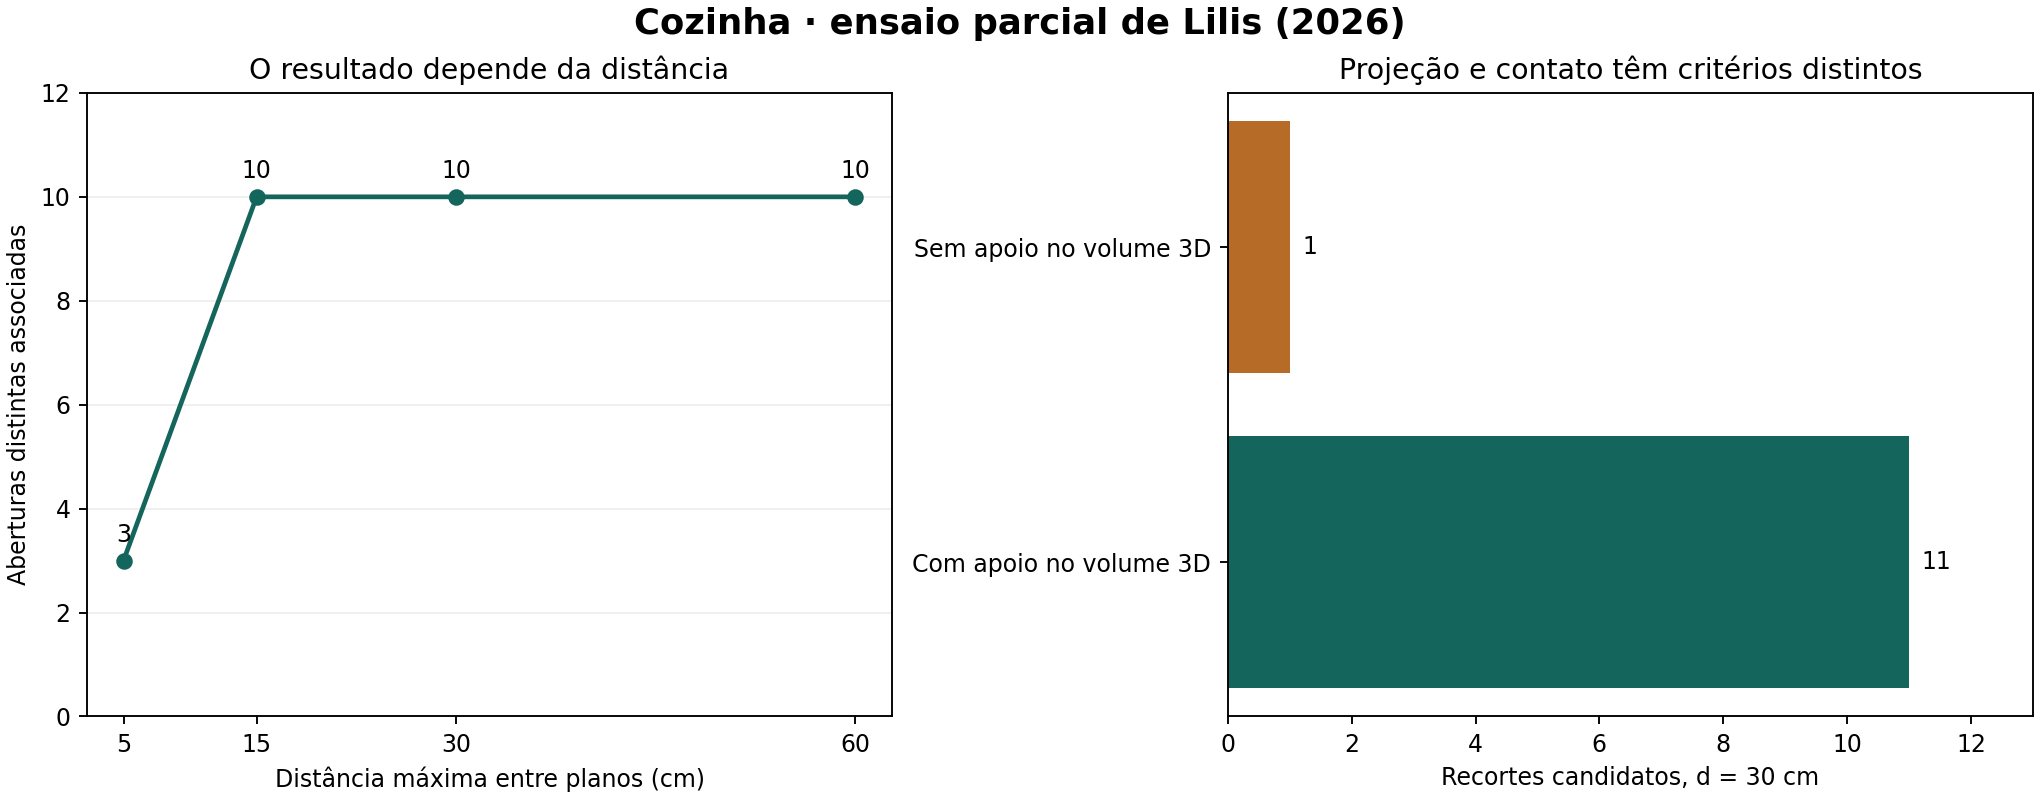

Relatório: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\lilis_2026_v01\execucao_notebook\resultados\Relatorio_Lilis_Hibrido_v01.html


In [7]:
# 7. Gera os arquivos de apresentação sem alterar as relações.
from apresentar_lilis import run as apresentar
apresentar(SAIDA)
from IPython.display import display,Image
display(Image(filename=str(SAIDA/'Comparacao_Lilis_v01.png')))
print('Relatório:',SAIDA/'Relatorio_Lilis_Hibrido_v01.html')


## O que podemos concluir

**Contribuição observada:** operadores de projeção e subtração foram incorporados e testados como alternativa rastreável no híbrido. Eles permitem comparar os recortes de abertura e calcular resíduos sem dupla subtração. O ensaio não aumentou o conjunto das dez aberturas associadas e não demonstrou melhora de acurácia arquitetônica.

**Ainda falta:** examinar o recorte adicional no projeto; validar as relações arquitetônicas independentemente; tratar as condições geométricas dos demais espaços; implementar e testar alpha wrap se for necessário reproduzir o método integral. Não temos uma classificação externa certificada nem a ontologia completa dos 41 cômodos.

**Fontes reutilizadas:** [Kiavarz et al. (2023)](https://doi.org/10.3390/buildings13020350), adaptação anterior de faces e interfaces; [Fichter et al. (2021)/IFC2SB](https://doi.org/10.26868/25222708.2021.30156), helper de geometria e recortes anteriores; [Krijnen et al. (2020)](https://doi.org/10.46421/2706-6568.37.2020.paper008), avaliações geométricas anteriores preservadas no RDF. Os módulos reutilizados são parciais. A atribuição e a licença GPL do helper IFC2SB acompanham o pacote; o PDF de Lilis tem licença CC BY.

O registro `Fontes_e_Adaptacoes_Lilis_v01.json` contém a referência completa, hash do PDF, rotinas, seções, decisões e limites.

In [8]:
# 8. Verificação final: IFC, preservação RDF, controles, parâmetros e versões.
assert hashlib.sha256(IFC.read_bytes()).hexdigest()==IFC_SHA
anterior=rdflib.Graph().parse(ENTRADA/'Cozinha_Interfaces_Hibridas_IFC2SB_Krijnen_Kiavarz_v01.ttl',format='turtle')
assert set(anterior).issubset(set(g))
assert registro['roundtrip_sem_alteracao'] and registro['novas_adjacencias_BOT_certificadas']==0
verificacao={'controles':20,'triplas_anteriores':len(anterior),'triplas_saida':len(g),'aberturas_distintas':10,'recortes_candidatos':12,'recortes_com_apoio_3D':11,'recortes_sem_apoio_3D':1,'ifc_preservado':True,'validacao_arquitetonica':'pendente','alpha_wrap_executado':False,'snapshot_pacote':SNAPSHOT}
(SAIDA/'Verificacao_Final.json').write_text(json.dumps(verificacao,ensure_ascii=False,indent=2),encoding='utf8')
versoes={'python':sys.version,'numpy':numpy.__version__,'ifcopenshell':ifcopenshell.version,'OCP':OCP.__version__,'shapely':shapely.__version__,'rdflib':rdflib.__version__,'matplotlib':matplotlib.__version__}
(SAIDA/'Ambiente_Execucao.json').write_text(json.dumps(versoes,ensure_ascii=False,indent=2),encoding='utf8')
print(json.dumps(verificacao,ensure_ascii=False,indent=2))


{
  "controles": 20,
  "triplas_anteriores": 2559,
  "triplas_saida": 3244,
  "aberturas_distintas": 10,
  "recortes_candidatos": 12,
  "recortes_com_apoio_3D": 11,
  "recortes_sem_apoio_3D": 1,
  "ifc_preservado": true,
  "validacao_arquitetonica": "pendente",
  "alpha_wrap_executado": false,
  "snapshot_pacote": "7507e4e318942ca7cd11b22f4a37a71cdeb9895d"
}
